### aim2 figure 1 (Distribution of time window with peak accuracy across participants.)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt

In [415]:
%matplotlib inline

In [3]:
plt.style.use('seaborn-darkgrid')
plt.style.use('seaborn-poster')

In [23]:
project_path = '/project_data/volume0/tpirnia/data/EEGWS/'

In [31]:
diag_ = pd.read_pickle('/project_data/volume0/tpirnia/data/EEGWS/data/across_subjects/results/all_subjects_diag.pkl')

In [32]:
result_path = '/project_data/volume0/tpirnia/data/EEGWS/data/across_subjects/results/'

In [33]:
main_df = pd.read_csv(result_path + 'clean/main_results.csv')
sliding_df = pd.read_csv(result_path + 'clean/sliding_window_df.csv')
beh_df = pd.read_csv(result_path + 'clean/behavior.csv')


In [34]:
main_df.head()

,Subject,Classifier,trial_window,trial_train_accuracy,trial_test_accuracy,window,step,w_train,w_train_accuracy,w_test_accuracy,lex_window,lex_train_accuracy,lex_test_accuracy,RT,RT_straight,RT_reverse,Interference_effect,Duration,Duration_straight,Duration_reverse
0,EP03,Ridge Classifier,1000,0.665,0.666667,50,10,0,0.541667,0.466667,350,0.62,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794
1,EP03,Ridge Classifier,1000,0.665,0.666667,50,10,1,0.585000,0.400000,350,0.62,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794
2,EP03,Ridge Classifier,1000,0.665,0.666667,50,10,2,0.568333,0.433333,350,0.62,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794
3,EP03,Ridge Classifier,1000,0.665,0.666667,50,10,3,0.570000,0.450000,350,0.62,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794
4,EP03,Ridge Classifier,1000,0.665,0.666667,50,10,4,0.593333,0.483333,350,0.62,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794


In [35]:
sliding_df.head()

,Subject,w_train,window,step,train_accuracy,t_0,t_10,t_20,t_30,t_40,...,t_1360,t_1370,t_1380,t_1390,t_1400,t_1410,t_1420,t_1430,t_1440,t_1450
0,EP03,0,50,10,0.541667,0.466667,0.433333,0.566667,0.583333,0.650000,...,0.416667,0.416667,0.483333,0.400000,0.383333,0.383333,0.416667,0.466667,0.400000,0.433333
1,EP03,1,50,10,0.585000,0.483333,0.400000,0.450000,0.500000,0.583333,...,0.450000,0.466667,0.416667,0.466667,0.400000,0.400000,0.466667,0.466667,0.433333,0.383333
2,EP03,2,50,10,0.568333,0.483333,0.500000,0.433333,0.433333,0.516667,...,0.516667,0.450000,0.466667,0.466667,0.433333,0.383333,0.416667,0.450000,0.450000,0.416667
3,EP03,3,50,10,0.570000,0.533333,0.466667,0.433333,0.450000,0.483333,...,0.483333,0.416667,0.350000,0.433333,0.433333,0.466667,0.416667,0.416667,0.466667,0.483333
4,EP03,4,50,10,0.593333,0.583333,0.516667,0.466667,0.466667,0.483333,...,0.483333,0.466667,0.450000,0.383333,0.383333,0.466667,0.466667,0.400000,0.433333,0.466667


In [50]:
diag_.head()

,subject,w_train,window,step,train_accuracy,t_0,t_10,t_20,t_30,t_40,...,t_1430,t_1440,t_1450,test_accuracy,RT_reverse,RT_straight,interference_effect,full_test_accuracy,best_train_test_accuracy,best_train_test_time
0,EP03,0,50,10,0.541667,0.466667,0.433333,0.566667,0.583333,0.650000,...,0.466667,0.400000,0.433333,0.466667,0.610754,0.57912,0.031634,0.733333,0.733333,0.69
1,EP03,1,50,10,0.585000,0.483333,0.400000,0.450000,0.500000,0.583333,...,0.466667,0.433333,0.383333,0.400000,0.610754,0.57912,0.031634,0.733333,0.733333,0.69
2,EP03,2,50,10,0.568333,0.483333,0.500000,0.433333,0.433333,0.516667,...,0.450000,0.450000,0.416667,0.433333,0.610754,0.57912,0.031634,0.733333,0.733333,0.69
3,EP03,3,50,10,0.570000,0.533333,0.466667,0.433333,0.450000,0.483333,...,0.416667,0.466667,0.483333,0.450000,0.610754,0.57912,0.031634,0.733333,0.733333,0.69
4,EP03,4,50,10,0.593333,0.583333,0.516667,0.466667,0.466667,0.483333,...,0.400000,0.433333,0.466667,0.483333,0.610754,0.57912,0.031634,0.733333,0.733333,0.69


In [70]:
diag_.melt(id_vars=['subject'],value_vars='best_train_test_accuracy').drop_duplicates()

,subject,variable,value
0,EP03,best_train_test_accuracy,0.733333
146,EP05,best_train_test_accuracy,0.733333
292,EP06,best_train_test_accuracy,0.783333
438,EP07,best_train_test_accuracy,0.933333
584,EP09,best_train_test_accuracy,0.716667
730,EP10,best_train_test_accuracy,0.900000
876,EP11,best_train_test_accuracy,0.733333
1022,EP12,best_train_test_accuracy,0.816667
1168,EP13,best_train_test_accuracy,0.833333
1314,EP14,best_train_test_accuracy,0.800000


In [239]:
diag_

,subject,w_train,window,step,train_accuracy,t_0,t_10,t_20,t_30,t_40,...,t_1430,t_1440,t_1450,test_accuracy,RT_reverse,RT_straight,interference_effect,full_test_accuracy,best_train_test_accuracy,best_train_test_time
0,EP03,0,50,10,0.541667,0.466667,0.433333,0.566667,0.583333,0.650000,...,0.466667,0.400000,0.433333,0.466667,0.610754,0.579120,0.031634,0.733333,0.733333,0.69
1,EP03,1,50,10,0.585000,0.483333,0.400000,0.450000,0.500000,0.583333,...,0.466667,0.433333,0.383333,0.400000,0.610754,0.579120,0.031634,0.733333,0.733333,0.69
2,EP03,2,50,10,0.568333,0.483333,0.500000,0.433333,0.433333,0.516667,...,0.450000,0.450000,0.416667,0.433333,0.610754,0.579120,0.031634,0.733333,0.733333,0.69
3,EP03,3,50,10,0.570000,0.533333,0.466667,0.433333,0.450000,0.483333,...,0.416667,0.466667,0.483333,0.450000,0.610754,0.579120,0.031634,0.733333,0.733333,0.69
4,EP03,4,50,10,0.593333,0.583333,0.516667,0.466667,0.466667,0.483333,...,0.400000,0.433333,0.466667,0.483333,0.610754,0.579120,0.031634,0.733333,0.733333,0.69
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4083,EP33,141,50,10,0.545000,0.500000,0.500000,0.500000,0.500000,0.483333,...,0.666667,0.633333,0.650000,0.650000,0.659374,0.556615,0.102759,0.716667,0.716667,0.89
4084,EP33,142,50,10,0.578333,0.450000,0.450000,0.500000,0.533333,0.500000,...,0.583333,0.616667,0.633333,0.633333,0.659374,0.556615,0.102759,0.716667,0.716667,0.89
4085,EP33,143,50,10,0.561667,0.466667,0.483333,0.466667,0.483333,0.516667,...,0.533333,0.533333,0.566667,0.533333,0.659374,0.556615,0.102759,0.716667,0.716667,0.89
4086,EP33,144,50,10,0.595000,0.466667,0.466667,0.516667,0.500000,0.533333,...,0.566667,0.516667,0.533333,0.516667,0.659374,0.556615,0.102759,0.716667,0.716667,0.89


In [238]:
diag_.melt(id_vars=['subject','best_train_test_time','best_train_test_accuracy'],value_vars='interference_effect').drop_duplicates()

,subject,best_train_test_time,best_train_test_accuracy,variable,value
0,EP03,0.69,0.733333,interference_effect,0.031634
146,EP05,0.55,0.733333,interference_effect,0.042467
292,EP06,0.79,0.783333,interference_effect,0.068941
438,EP07,0.61,0.933333,interference_effect,0.142981
584,EP09,0.71,0.716667,interference_effect,0.178776
730,EP10,0.65,0.900000,interference_effect,0.155745
876,EP11,0.95,0.733333,interference_effect,0.035015
1022,EP12,0.51,0.816667,interference_effect,0.093455
1168,EP13,0.65,0.833333,interference_effect,0.133859
1314,EP14,0.55,0.800000,interference_effect,0.148406


In [53]:
_diag0 = np.array(diag_[(diag_['subject']=='EP07')& (diag_['w_train']>=50))].iloc[:,55:-7])

In [64]:
# times = np.arange(0,1001,10)
# times[np.argmax(_diag0,axis=2)]

max_ind = np.unravel_index(_diag0.argmax(), _diag0.shape)


In [85]:
times[max_ind[0]]
times[max_ind[1]]

560

In [95]:
for s in diag_.subject.unique():
    _diag0 = np.array(diag_[(diag_['subject']==s)& (diag_['w_train']>=50)].iloc[:,55:-7])
    max_ind = np.unravel_index(_diag0.argmax(), _diag0.shape)
    print(s, _diag0[max_ind], np.argwhere(_diag0==_diag0[max_ind]))

EP03 0.75 [[87 82]]
EP05 0.7333333333333333 [[55 55]]
EP06 0.7833333333333333 [[79 79]]
EP07 0.9333333333333332 [[55 56]
 [57 56]
 [61 61]]
EP09 0.7333333333333333 [[83 93]
 [84 92]]
EP10 0.9333333333333332 [[65 62]
 [72 68]
 [73 69]]
EP11 0.75 [[40 46]
 [95 92]]
EP12 0.8166666666666667 [[51 51]
 [53 55]
 [54 59]
 [55 56]
 [55 58]]
EP13 0.85 [[65 63]
 [71 66]
 [76 72]]
EP14 0.8166666666666667 [[49 51]]
EP15 0.7 [[26 22]
 [41 52]
 [80 85]
 [80 87]]
EP16 0.8 [[72 76]
 [86 74]]
EP17 0.7833333333333333 [[43 48]]
EP18 0.8 [[29 29]
 [42 38]
 [43 39]
 [43 40]]
EP19 0.7666666666666667 [[52 72]
 [71 71]
 [91 93]]
EP20 0.8333333333333334 [[57 58]]
EP21 0.75 [[3 2]]
EP22 0.7833333333333333 [[40 41]]
EP23 0.8333333333333334 [[46 49]]
EP25 0.9333333333333332 [[65 67]]
EP26 0.75 [[42 44]
 [74 76]
 [82 77]]
EP27 0.7166666666666667 [[72 84]]
EP28 0.8333333333333334 [[46 48]
 [46 51]
 [46 52]]
EP29 0.7166666666666667 [[66 59]]
EP30 0.7333333333333333 [[50 41]
 [51 48]
 [78 77]]
EP31 0.8 [[55 51]
 [77 7

In [104]:
main_df['w_best_diag_accuracy']=0
main_df['w_best_diag_time']=0

for s in diag_.subject.unique():
    _diag0 = np.array(diag_[(diag_['subject']==s)& (diag_['w_train']>=50)].iloc[:,55:-7])
    #max_ind = np.diagonal(_diag0).argmax()
    print(s, np.argmax(np.diagonal(_diag0)), np.max(np.diagonal(_diag0)))
    main_df['w_best_diag_time'][main_df['Subject']==s]= np.argmax(np.diagonal(_diag0))*10
    main_df['w_best_diag_accuracy'][main_df['Subject']==s]= np.max(np.diagonal(_diag0))

EP03 69 0.7333333333333333
EP05 55 0.7333333333333333
EP06 79 0.7833333333333333
EP07 61 0.9333333333333332
EP09 71 0.7166666666666667
EP10 65 0.9
EP11 95 0.7333333333333333
EP12 51 0.8166666666666667
EP13 65 0.8333333333333334
EP14 55 0.8
EP15 52 0.6666666666666666
EP16 89 0.7666666666666667
EP17 42 0.7
EP18 29 0.8
EP19 71 0.7666666666666667
EP20 58 0.7833333333333333
EP21 3 0.7166666666666667
EP22 38 0.7666666666666667
EP23 46 0.75
EP25 57 0.9166666666666666
EP26 60 0.7166666666666667
EP27 95 0.6666666666666666
EP28 53 0.8
EP29 46 0.6666666666666666
EP30 73 0.7166666666666667
EP31 77 0.8
EP32 87 0.7


/home/tpirnia/miniconda3/envs/python36c2/lib/python3.6/site-packages/ipykernel_launcher.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  
/home/tpirnia/miniconda3/envs/python36c2/lib/python3.6/site-packages/ipykernel_launcher.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  if __name__ == '__main__':
/home/tpirnia/miniconda3/envs/python36c2/lib/python3.6/site-packages/ipykernel_launcher.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-

EP33 89 0.7166666666666667


/home/tpirnia/miniconda3/envs/python36c2/lib/python3.6/site-packages/ipykernel_launcher.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  if __name__ == '__main__':


In [115]:
len(main_df['Subject'].unique())

28

In [320]:
main_by_subj = pd.concat([main_df.iloc[:,:7],main_df.iloc[:,-12:]],axis=1).drop_duplicates()

In [321]:
main_by_subj.reset_index(inplace=True)

In [322]:
main_by_subj.head()

,index,Subject,Classifier,trial_window,trial_train_accuracy,trial_test_accuracy,window,step,lex_window,lex_train_accuracy,lex_test_accuracy,RT,RT_straight,RT_reverse,Interference_effect,Duration,Duration_straight,Duration_reverse,w_best_diag_accuracy,w_best_diag_time
0,0,EP03,Ridge Classifier,1000,0.665000,0.666667,50,10,350,0.620000,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794,0.733333,690
1,146,EP05,Ridge Classifier,1000,0.578333,0.650000,50,10,350,0.580000,0.616667,0.586500,0.557460,0.615735,0.104538,0.473641,0.478883,0.468364,0.733333,550
2,292,EP06,Ridge Classifier,1000,0.721667,0.716667,50,10,350,0.623333,0.650000,0.771049,0.739425,0.802461,0.085249,0.425675,0.427492,0.423869,0.783333,790
3,438,EP07,Ridge Classifier,1000,0.933333,0.916667,50,10,350,0.653333,0.633333,0.676477,0.609939,0.744604,0.220783,0.505401,0.502810,0.508045,0.933333,610
4,584,EP09,Ridge Classifier,1000,0.583333,0.616667,50,10,350,0.516667,0.483333,0.702270,0.615556,0.794122,0.290090,0.519242,0.512091,0.526790,0.716667,710


In [28]:
diag_.groupby(by=['subject','best_train_test_time'],as_index=False).max()
# tmp_df_summary['best_train_test_time']*1000

,subject,best_train_test_time,w_train,window,step,train_accuracy,t_0,t_10,t_20,t_30,...,t_1420,t_1430,t_1440,t_1450,test_accuracy,RT_reverse,RT_straight,interference_effect,full_test_accuracy,best_train_test_accuracy
0,EP03,0.69,145,50,10,0.705000,0.683333,0.650000,0.666667,0.700000,...,0.666667,0.716667,0.683333,0.666667,0.733333,0.610754,0.579120,0.031634,0.733333,0.733333
1,EP05,0.55,145,50,10,0.635000,0.716667,0.716667,0.733333,0.750000,...,0.616667,0.600000,0.583333,0.633333,0.766667,0.608435,0.565968,0.042467,0.766667,0.733333
2,EP06,0.79,145,50,10,0.735000,0.600000,0.600000,0.616667,0.600000,...,0.683333,0.666667,0.733333,0.683333,0.783333,0.813343,0.744401,0.068941,0.783333,0.783333
3,EP07,0.61,145,50,10,0.936667,0.700000,0.666667,0.666667,0.650000,...,0.766667,0.766667,0.783333,0.766667,0.933333,0.750758,0.607777,0.142981,0.933333,0.933333
4,EP09,0.71,145,50,10,0.681667,0.616667,0.616667,0.616667,0.616667,...,0.733333,0.733333,0.716667,0.700000,0.716667,0.808178,0.629402,0.178776,0.716667,0.716667
5,EP10,0.65,145,50,10,0.896667,0.700000,0.700000,0.716667,0.716667,...,0.783333,0.816667,0.833333,0.816667,0.900000,0.730146,0.574401,0.155745,0.900000,0.900000
6,EP11,0.95,145,50,10,0.695000,0.616667,0.650000,0.600000,0.600000,...,0.750000,0.733333,0.716667,0.733333,0.733333,0.662215,0.627200,0.035015,0.733333,0.733333
7,EP12,0.51,145,50,10,0.768333,0.666667,0.600000,0.616667,0.666667,...,0.616667,0.683333,0.650000,0.650000,0.816667,0.620548,0.527093,0.093455,0.816667,0.816667
8,EP13,0.65,145,50,10,0.816667,0.633333,0.633333,0.616667,0.583333,...,0.766667,0.766667,0.783333,0.783333,0.833333,0.712154,0.578295,0.133859,0.833333,0.833333
9,EP14,0.55,145,50,10,0.813333,0.583333,0.583333,0.600000,0.600000,...,0.666667,0.650000,0.616667,0.616667,0.800000,0.765687,0.617281,0.148406,0.800000,0.800000


In [380]:
#plot parameters:
params = {'lines.markersize':6,
          'axes.labelsize': 20,
          'axes.titlesize':20,
          'axes.labelpad':8,
          'xtick.labelsize' :16,
          'ytick.labelsize' :16,
          'xtick.major.pad':7, 
          'ytick.major.pad':6, 
          'legend.labelspacing':.5,
          'legend.handletextpad':.175,
          'legend.title_fontsize':20,
          'legend.fontsize':20,
          'figure.figsize':(8,10),
          'figure.subplot.hspace': .3,
          'figure.subplot.wspace': .3,
          'image.origin': 'lower',
          'figure.autolayout': False,
          'scatter.marker':'o',
          'savefig.dpi': 450,
          'savefig.bbox': 'tight',
          'savefig.transparent': True,
         }
#'axes.prop_cycle':,""
# @mpl.rc_context(params)
#plt.gca().set_aspect('equal', adjustable='box')

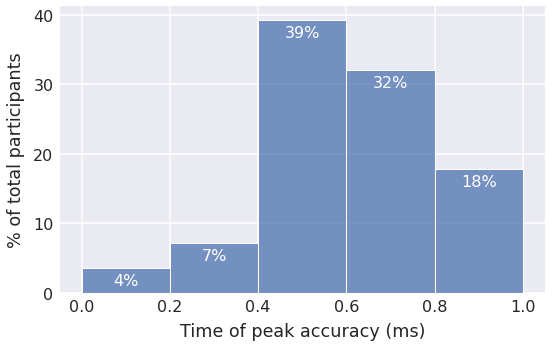

In [411]:
import matplotlib as mpl
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')

    fig, ax = plt.subplots(figsize=(8.7, 5.27))
    p = sns.histplot(data=diag_, 
                     x='best_train_test_time', 
                     stat='percent', 
                     binwidth=.2, 
                     binrange=(0,1), 
                     edgecolor="white",
                     linewidth=1,
                     ax=ax)

    for h in p.patches:
        height = h.get_height() 
        if height == 0: vert = + .35; color='gray'
        else: vert = -2.5; color='white'
        p.text(x = h.get_x() + (h.get_width()/2),
               y = height + vert, 
               s = '{:.0f}%'.format(height), 
               ha = 'center',
               fontsize=16,
               color=color,
              ) 
    plt.xlabel('Time of peak accuracy (ms)')
    plt.ylabel('% of total participants')
    # plt.xlim(0,.95)
    plt.tick_params(axis='both',pad=6)
    figname = 'across_subject_distribution_of_peak_acc_across_time_w50s10_ridge_0.2bin-labeled-2.png'
    plt.savefig(result_path + '/clean/aim-2/'+ figname, dpi=450, bbox_inches = "tight", transparent=True)
    plt.show()

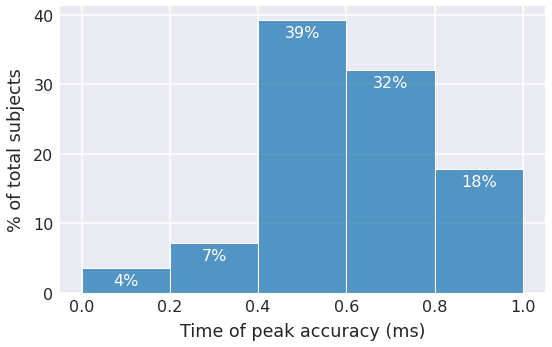

In [201]:
import matplotlib as mpl
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')

    fig, ax = plt.subplots(figsize=(8.7, 5.27))
    p = sns.histplot(data=diag_, 
                     x='best_train_test_time', 
                     stat='percent', 
                     binwidth=.2, 
                     binrange=(0,1), 
                     edgecolor="white",
                     linewidth=1,
                     ax=ax)

    for h in p.patches:
        height = h.get_height() 
        if height == 0: vert = + .35; color='gray'
        else: vert = -2.5; color='white'
        p.text(x = h.get_x() + (h.get_width()/2),
               y = height + vert, 
               s = '{:.0f}%'.format(height), 
               ha = 'center',
               fontsize=16,
               color=color,
              ) 
    plt.xlabel('Time of peak accuracy (ms)')
    plt.ylabel('% of total subjects')
    # plt.xlim(0,.95)
    plt.tick_params(axis='both',pad=6)
    figname = 'across_subject_distribution_of_peak_acc_across_time_w50s10_ridge_0.2bin-labeled-3.png'
    plt.savefig(result_path + '/clean/aim-2/'+ figname, dpi=450, bbox_inches = "tight", transparent=True)
    plt.show()

In [319]:
main_df.iloc[:,-12:]

,lex_window,lex_train_accuracy,lex_test_accuracy,RT,RT_straight,RT_reverse,Interference_effect,Duration,Duration_straight,Duration_reverse,w_best_diag_accuracy,w_best_diag_time
0,350,0.620000,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794,0.733333,690
1,350,0.620000,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794,0.733333,690
2,350,0.620000,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794,0.733333,690
3,350,0.620000,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794,0.733333,690
4,350,0.620000,0.616667,0.588881,0.575113,0.602511,0.047638,0.383838,0.384892,0.382794,0.733333,690
...,...,...,...,...,...,...,...,...,...,...,...,...
4083,350,0.593333,0.550000,0.592356,0.544490,0.641048,0.177336,0.425002,0.423024,0.427013,0.716667,890
4084,350,0.593333,0.550000,0.592356,0.544490,0.641048,0.177336,0.425002,0.423024,0.427013,0.716667,890
4085,350,0.593333,0.550000,0.592356,0.544490,0.641048,0.177336,0.425002,0.423024,0.427013,0.716667,890
4086,350,0.593333,0.550000,0.592356,0.544490,0.641048,0.177336,0.425002,0.423024,0.427013,0.716667,890


In [323]:
main_by_subj.columns

Index(['index', 'Subject', 'Classifier', 'trial_window',
       'trial_train_accuracy', 'trial_test_accuracy', 'window', 'step',
       'lex_window', 'lex_train_accuracy', 'lex_test_accuracy', 'RT',
       'RT_straight', 'RT_reverse', 'Interference_effect', 'Duration',
       'Duration_straight', 'Duration_reverse', 'w_best_diag_accuracy',
       'w_best_diag_time'],
      dtype='object')

In [ ]:
# = test_df['train_accuracy'].astype(np.float)
# test_df.apply(pd.to_numeric, errors='ignore')

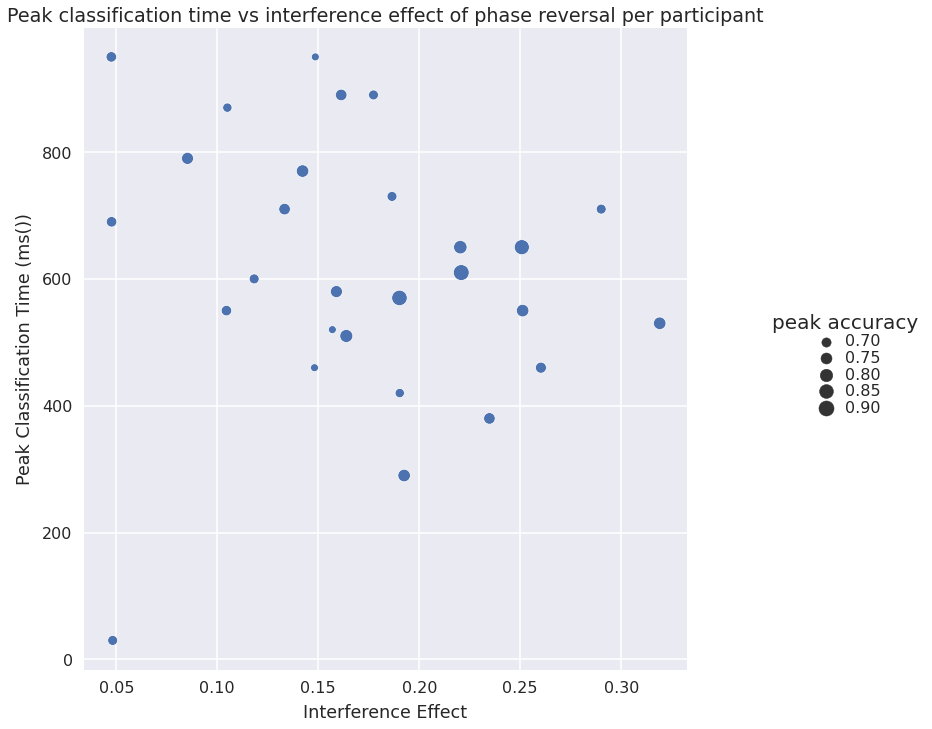

In [329]:
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    g = sns.relplot(
        data=main_by_subj,
        x="Interference_effect", y="w_best_diag_time",
        size="w_best_diag_accuracy",legend=True, height=10)
    g.set(xlabel="Interference Effect", ylabel="Peak Classification Time (ms())",title='Peak classification time vs interference effect of phase reversal per participant')
    g.legend.set_title('peak accuracy')


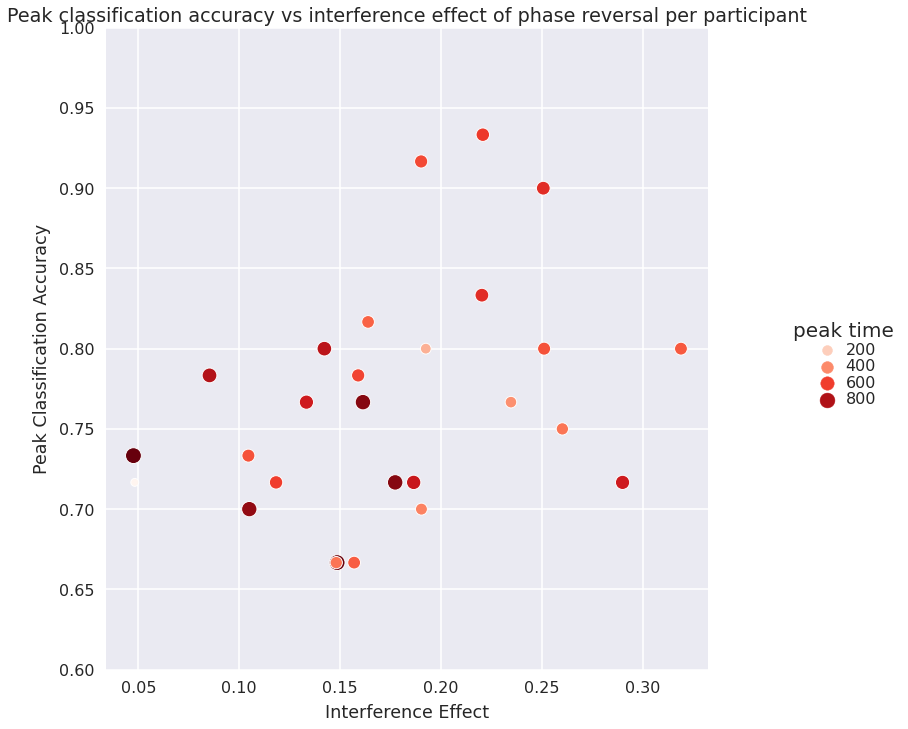

In [327]:
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    cmap = plt.get_cmap('Reds') 
    # cmap = sns.cubehelix_palette(rot=-.2, as_cmap=True)
    g = sns.relplot(
        data=main_by_subj,
        x="Interference_effect", y="w_best_diag_accuracy",
        hue="w_best_diag_time",size='w_best_diag_time',legend=True, height=10,palette=cmap)

    g.set(xlabel="Interference Effect", ylabel="Peak Classification Accuracy",ylim=(.6,1),title='Peak classification accuracy vs interference effect of phase reversal per participant')

In [ ]:
Index(['index', 'Subject', 'Classifier', 'trial_window',
       'trial_train_accuracy', 'trial_test_accuracy', 'window', 'step',
       'lex_window', 'lex_train_accuracy', 'lex_test_accuracy', 'RT',
       'RT_straight', 'RT_reverse', 'Interference_effect', 'Duration',
       'Duration_straight', 'Duration_reverse', 'w_best_diag_accuracy',
       'w_best_diag_time'],
      dtype='object')

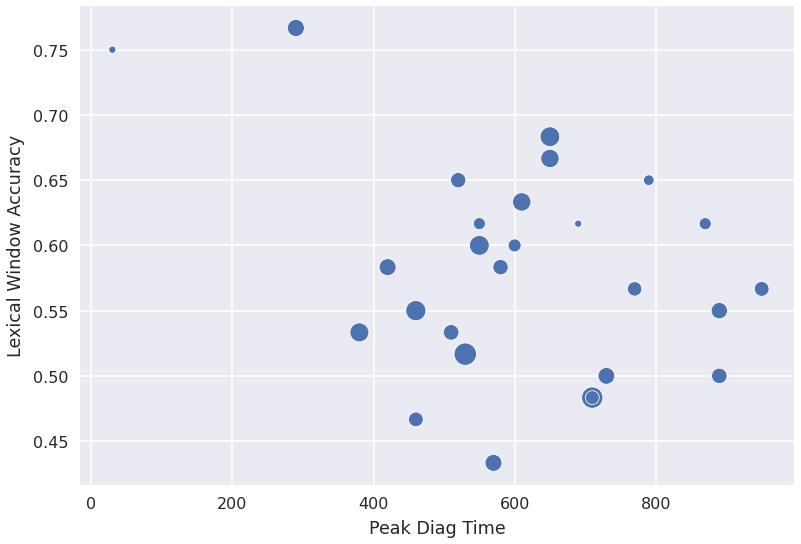

In [371]:
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    cmap = plt.get_cmap('Reds') 
    linecol = cmap(np.linspace(0,1,28))
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    g = sns.scatterplot(
        data=main_by_subj,
        y="lex_test_accuracy", x="w_best_diag_time",
        size="Interference_effect",legend=False,# height=10,#,palette=cmap,
        sizes=(50, 500),)

    g.set(ylabel="Lexical Window Accuracy", xlabel="Peak Diag Time")#,ylim=(.6,1))
#     sns.scatterplot(x='w_best_diag_time',y='lex_test_accuracy', data=main_by_subj,hue='Subject')
#     g = sns.relplot(
#         data=main_by_subj,
#         x="w_best_diag_time", y="lex_test_accuracy",
#         size="Duration_reverse",hue='Interference_effect',legend=True, height=10,palette='Blues',
#         sizes=(50, 500),)
# #     g.legend.set_title('Interference Effect')

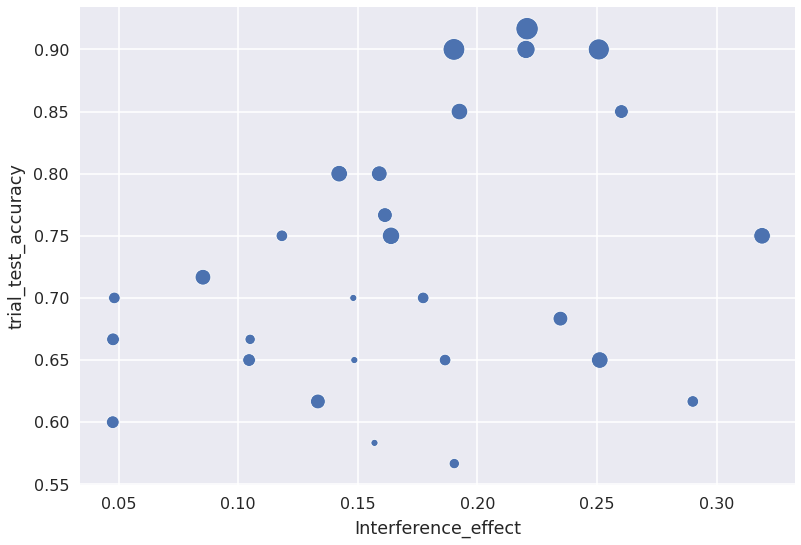

In [375]:
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    cmap = plt.get_cmap('Reds') 
    linecol = cmap(np.linspace(0,1,28))
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    g = sns.scatterplot(
        data=main_by_subj,
        y="trial_test_accuracy", x="Interference_effect",legend=False,size='w_best_diag_accuracy',# height=10,#,palette=cmap,
        sizes=(50, 500),)

    g.set(ylabel="trial_test_accuracy", xlabel="Interference_effect")#,ylim=(.6,1))
#     sns.scatterplot(x='w_best_diag_time',y='lex_test_accuracy', data=main_by_subj,hue='Subject')
#     g = sns.relplot(
#         data=main_by_subj,
#         x="w_best_diag_time", y="lex_test_accuracy",
#         size="Duration_reverse",hue='Interference_effect',legend=True, height=10,palette='Blues',
#         sizes=(50, 500),)
# #     g.legend.set_title('Interference Effect')

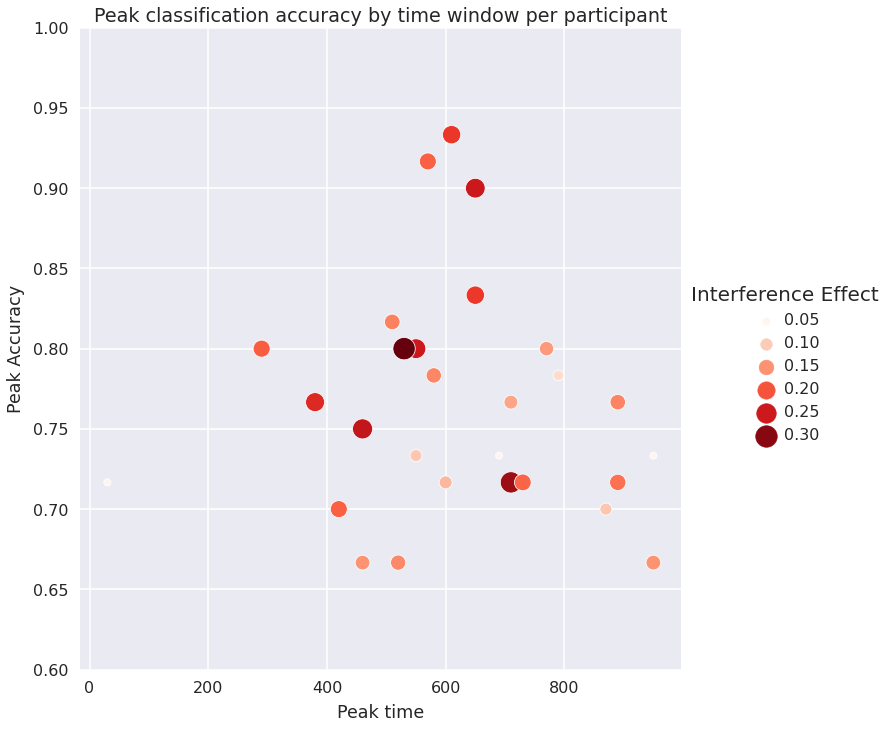

In [381]:
with mpl.rc_context(params):

    cmap = plt.get_cmap('Reds') 
    linecol = cmap(np.linspace(.2,1,28))
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    g = sns.relplot(
        data=main_by_subj,
        x="w_best_diag_time", y="w_best_diag_accuracy",
        hue="Interference_effect",size='Interference_effect',legend=True, height=10,palette=cmap,
        sizes=(50, 500),)

    g.set(xlabel="Peak time", ylabel="Peak Accuracy",ylim=(.6,1),title='Peak classification accuracy by time window per participant')
    g.legend.set_title('Interference Effect')
    plt.savefig(result_path + '/clean/aim-2/peak_accuracy_time_interference.png', dpi=450, bbox_inches = "tight", transparent=True)


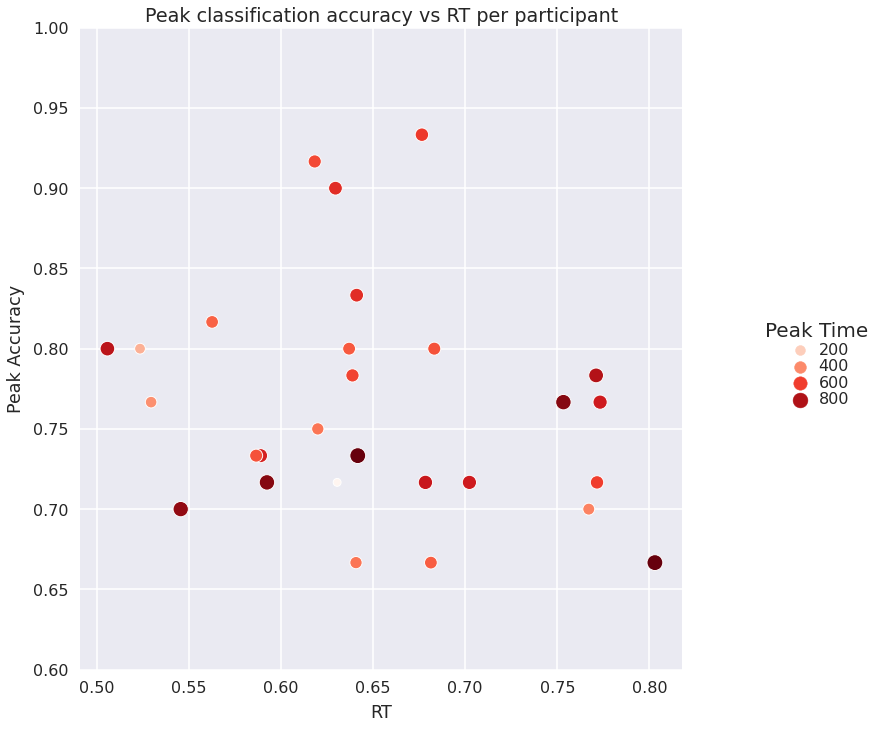

In [330]:
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    cmap = plt.get_cmap('Reds') 
    g = sns.relplot(
        data=main_by_subj,
        x="RT", y="w_best_diag_accuracy",
        hue="w_best_diag_time",size='w_best_diag_time',legend=True, height=10,palette=cmap)

    g.set(xlabel="RT", ylabel="Peak Accuracy",ylim=(.6,1),title='Peak classification accuracy vs RT per participant')
    g.legend.set_title('Peak Time')


In [386]:
np.shape(main_by_subj.corr())

(18, 18)

In [388]:
main_by_subj.corr().columns.values

array(['index', 'trial_window', 'trial_train_accuracy',
       'trial_test_accuracy', 'window', 'step', 'lex_window',
       'lex_train_accuracy', 'lex_test_accuracy', 'RT', 'RT_straight',
       'RT_reverse', 'Interference_effect', 'Duration',
       'Duration_straight', 'Duration_reverse', 'w_best_diag_accuracy',
       'w_best_diag_time'], dtype=object)

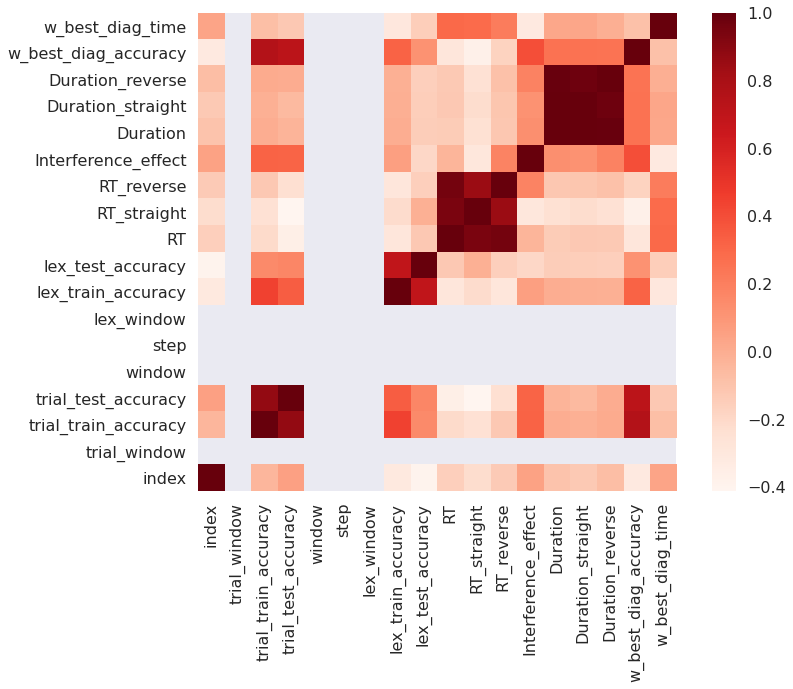

In [397]:
plt.imshow(main_by_subj.corr(method='spearman'),origin='lower',cmap='Reds')
plt.xticks(np.arange(18),main_by_subj.corr().columns.values,rotation=90)
plt.yticks(np.arange(18),main_by_subj.corr().columns.values,rotation=0)
plt.colorbar()
plt.grid(None)
plt.show()

In [398]:
from scipy.stats import pearsonr


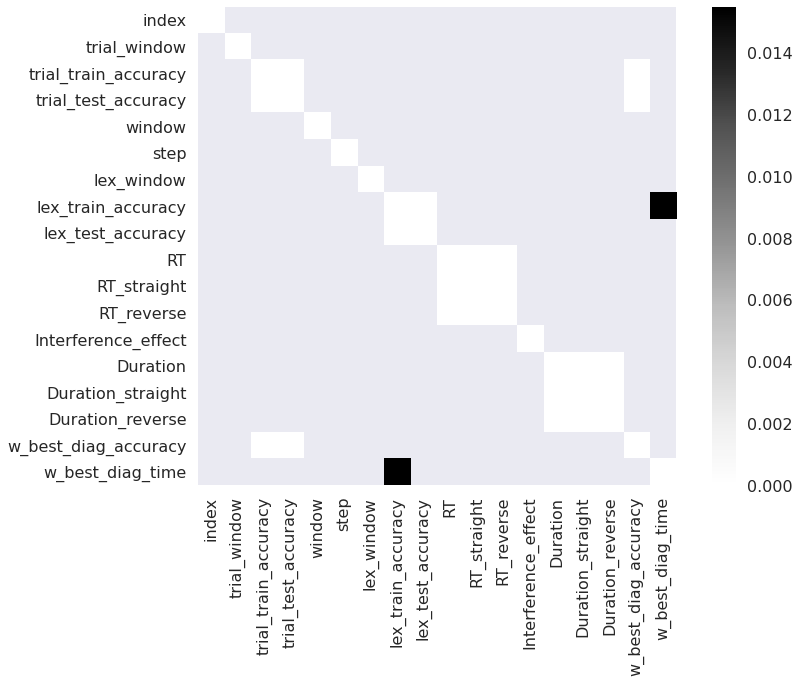

In [408]:
plt.imshow(pval[pval<0.05])
plt.xticks(np.arange(18),main_by_subj.corr().columns.values,rotation=90)
plt.yticks(np.arange(18),main_by_subj.corr().columns.values,rotation=0)
plt.grid(None)
plt.colorbar()
plt.show()

In [409]:
p

,index,trial_window,trial_train_accuracy,trial_test_accuracy,window,step,lex_window,lex_train_accuracy,lex_test_accuracy,RT,RT_straight,RT_reverse,Interference_effect,Duration,Duration_straight,Duration_reverse,w_best_diag_accuracy,w_best_diag_time
index,***,,,,,,,,,,,,,,,,,
trial_window,,***,,,,,,,,,,,,,,,,
trial_train_accuracy,,,***,***,,,,,,,,,,,,,***,
trial_test_accuracy,,,***,***,,,,,,,,,,,,,***,
window,,,,,***,,,,,,,,,,,,,
step,,,,,,***,,,,,,,,,,,,
lex_window,,,,,,,***,,,,,,,,,,,
lex_train_accuracy,,,,,,,,***,***,,,,,,,,,*
lex_test_accuracy,,,,,,,,***,***,,,,,,,,,
RT,,,,,,,,,,***,***,***,,,,,,


In [399]:
rho = main_by_subj.corr()
pval = main_by_subj.corr(method=lambda x, y: pearsonr(x, y)[1]) - np.eye(*rho.shape)
p = pval.applymap(lambda x: ''.join(['*' for t in [0.001,0.01,0.05] if x<=t]))
rho.round(2).astype(str) + ' ('+pval.round(20).astype(str)+')'+p

/home/tpirnia/miniconda3/envs/python36c2/lib/python3.6/site-packages/scipy/stats/stats.py:3845: PearsonRConstantInputWarning: An input array is constant; the correlation coefficent is not defined.
  warnings.warn(PearsonRConstantInputWarning())


,index,trial_window,trial_train_accuracy,trial_test_accuracy,window,step,lex_window,lex_train_accuracy,lex_test_accuracy,RT,RT_straight,RT_reverse,Interference_effect,Duration,Duration_straight,Duration_reverse,w_best_diag_accuracy,w_best_diag_time
index,1.0 (0.0)***,nan (nan),-0.07 (0.7251236528957333),0.0 (0.9956374877642713),nan (nan),nan (nan),nan (nan),-0.31 (0.10524862898678457),-0.33 (0.09114032970571191),-0.15 (0.4422037547361276),-0.17 (0.38801863960405786),-0.13 (0.5131379478895353),0.1 (0.6221326408267965),-0.12 (0.5487422977510532),-0.13 (0.49942662152019757),-0.1 (0.60107557796572),-0.3 (0.12724941250045535),0.04 (0.8363031771853282)
trial_window,nan (nan),nan (0.0)***,nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan)
trial_train_accuracy,-0.07 (0.7251236528957333),nan (nan),1.0 (0.0)***,0.91 (2.528537226e-11)***,nan (nan),nan (nan),nan (nan),0.36 (0.062828780918702),0.14 (0.4622721754520062),-0.17 (0.3845451642704606),-0.23 (0.24035457174855615),-0.11 (0.5673140838019803),0.28 (0.14304654933938632),0.01 (0.9571846357123743),-0.01 (0.9586510993375987),0.03 (0.8753990386144637),0.84 (1.676681748088e-08)***,-0.08 (0.6878866675016155)
trial_test_accuracy,0.0 (0.9956374877642713),nan (nan),0.91 (2.528537226e-11)***,1.0 (0.0)***,nan (nan),nan (nan),nan (nan),0.32 (0.09271081612372677),0.19 (0.3410782859854784),-0.3 (0.12586336602453047),-0.36 (0.05743037876404355),-0.22 (0.2509536446669131),0.33 (0.0856321156373711),-0.01 (0.9579679337518789),-0.04 (0.8421326000586701),0.02 (0.9274035960371365),0.79 (6.5917143868818e-07)***,-0.14 (0.47046711542553493)
window,nan (nan),nan (nan),nan (nan),nan (nan),nan (0.0)***,nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan)
step,nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (0.0)***,nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan)
lex_window,nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (0.0)***,nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan),nan (nan)
lex_train_accuracy,-0.31 (0.10524862898678457),nan (nan),0.36 (0.062828780918702),0.32 (0.09271081612372677),nan (nan),nan (nan),nan (nan),1.0 (0.0)***,0.8 (4.0571326696467e-07)***,-0.34 (0.07699056433357372),-0.31 (0.1046293194648747),-0.35 (0.07020068886785216),-0.04 (0.841387951375782),-0.06 (0.7680641506438708),-0.04 (0.8267483625106815),-0.07 (0.714710315234258),0.3 (0.11630011433266643),-0.45 (0.015497059681897326)*
lex_test_accuracy,-0.33 (0.09114032970571191),nan (nan),0.14 (0.4622721754520062),0.19 (0.3410782859854784),nan (nan),nan (nan),nan (nan),0.8 (4.0571326696467e-07)***,1.0 (0.0)***,-0.17 (0.37406583078659006),-0.11 (0.5879935698309954),-0.23 (0.23929520603964977),-0.25 (0.1999225484259592),-0.22 (0.2509245477550155),-0.2 (0.29853740723811395),-0.24 (0.2129150363167667),0.08 (0.6920037721450247),-0.35 (0.06548676116062398)
RT,-0.15 (0.4422037547361276),nan (nan),-0.17 (0.3845451642704606),-0.3 (0.12586336602453047),nan (nan),nan (nan),nan (nan),-0.34 (0.07699056433357372),-0.17 (0.37406583078659006),1.0 (0.0)***,0.97 (1.226e-17)***,0.98 (1.24e-18)***,-0.03 (0.8912090521954492),-0.23 (0.2457933839073312),-0.22 (0.25354374955152176),-0.23 (0.24144272465570776),-0.22 (0.265081847278421),0.26 (0.17805135693064142)


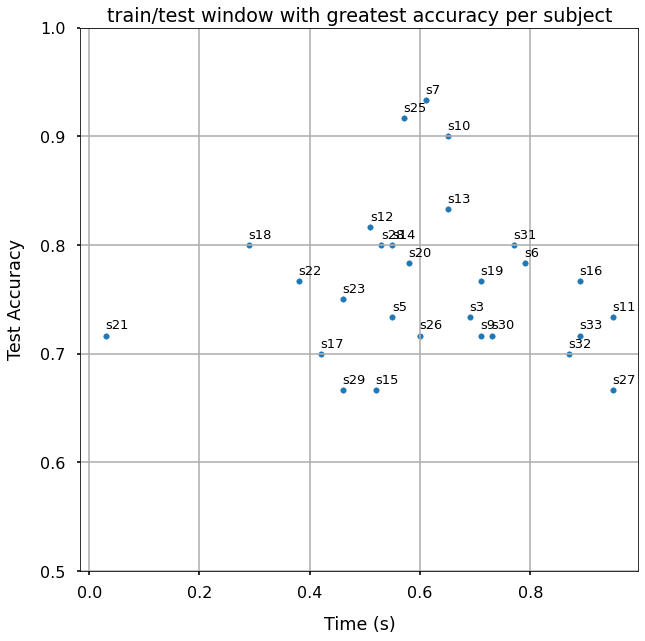

In [65]:
fig, ax = plt.subplots(figsize=(10,10))
plt.style.use('seaborn-poster')
x,y = zip(*max_acc)
plt.scatter(x,y,marker='o',c=s=)
plt.grid(True,'major','both')
plt.ylim(.5,1)
plt.ylabel('Test Accuracy',labelpad=15)
plt.xlabel('Time (s)',labelpad=15)
plt.title('train/test window with greatest accuracy per subject')
for i, txt in enumerate(SUBJECTS):
    ax.annotate('s'+str(np.int(txt[2:])), (x[i]-.001, y[i]+.00625),fontsize=13)


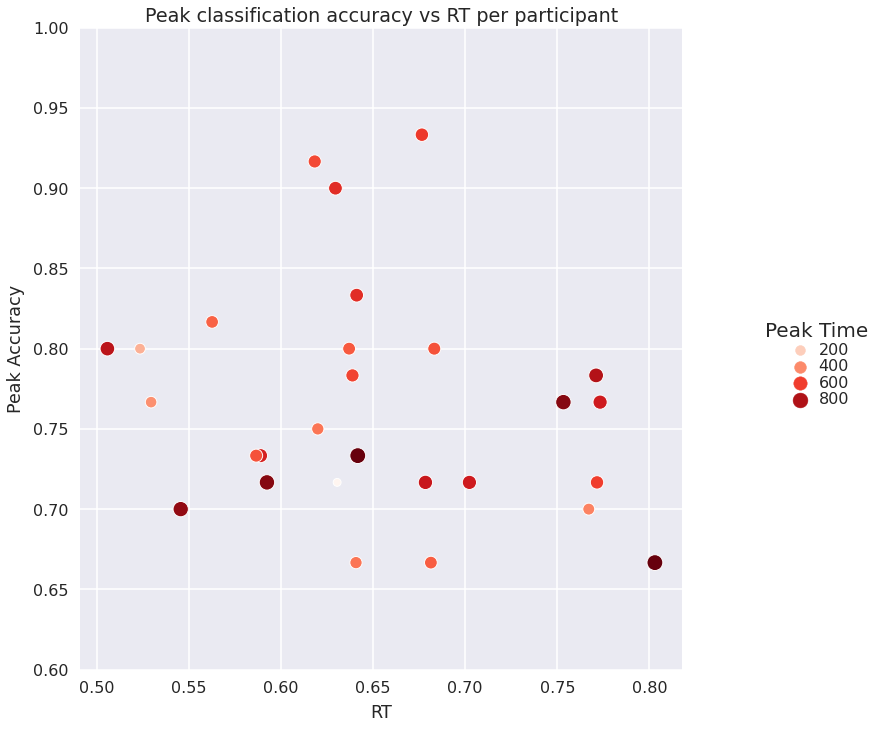

In [326]:
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')
    cmap = plt.get_cmap('Reds') 
        #linecol = cmap(np.linspace(0,.7,10))
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')

    g = sns.relplot(
        data=main_by_subj,
        x="RT", y="w_best_diag_accuracy",
        hue="w_best_diag_time",size='w_best_diag_time',legend=True, height=10,palette=cmap)

    g.set(xlabel="RT", ylabel="Peak Accuracy",ylim=(.6,1),title='Peak classification accuracy vs RT per participant')
    g.legend.set_title('Peak Time')


[(0.5, 1.0),
 Text(0, 0.5, 'peak diagonal accuracy'),
 Text(0.5, 0, 'interference effect')]

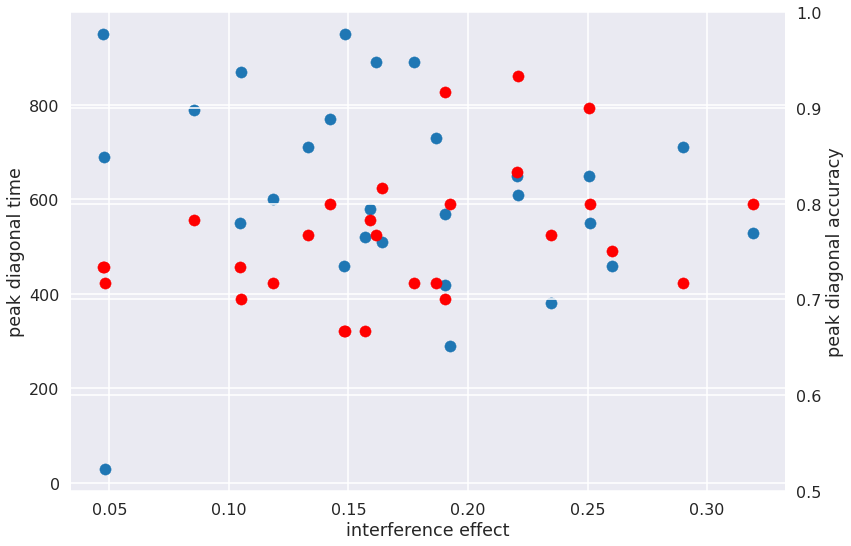

In [232]:
fig,ax = plt.subplots(1,1,)
plt.scatter(main_by_subj['Interference_effect'],main_by_subj['w_best_diag_time'])
ax.set(ylabel='peak diagonal time',xlabel='interference effect')
ax2 = ax.twinx()
plt.scatter(main_by_subj['Interference_effect'],main_by_subj['w_best_diag_accuracy'],c='Red')
ax2.set(ylabel='peak diagonal accuracy',xlabel='interference effect',ylim=[.5,1])


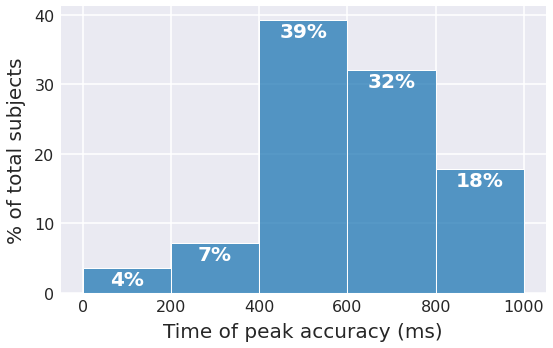

In [211]:
import matplotlib as mpl
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    plt.style.use('seaborn-poster')

    fig, ax = plt.subplots(figsize=(8.7, 5.27))
    p = sns.histplot(data=diag_, 
                     x='best_train_test_time', 
                     stat='percent', 
                     binwidth=.2, 
                     binrange=(0,1), 
                     edgecolor="white",
                     linewidth=1,
                     ax=ax)

    for h in p.patches:
        height = h.get_height() 
        if height == 0: vert = + .35; color='gray'
        else: vert = -2.5; color='white'
        p.text(x = h.get_x() + (h.get_width()/2),
               y = height + vert, 
               s = '{:.0f}%'.format(height), 
               ha = 'center',
               fontsize=20,
               color=color,
               fontweight="bold") 
    plt.xlabel('Time of peak accuracy (ms)',fontsize=20)
    plt.ylabel('% of total subjects',fontsize=20)

    plt.tick_params(axis='both',pad=6)
    plt.xticks(np.arange(0,101,20)/100,np.arange(0,1001,200))
    figname = 'across_subject_distribution_of_peak_acc_across_time_w50s10_ridge_0.2bin-labeled-2.png'
    plt.savefig(result_path + '/clean/aim-2/'+ figname, dpi=450, bbox_inches = "tight", transparent=False)
    plt.show()

In [ ]:
# to see plotting context:
print(sns.plotting_context())

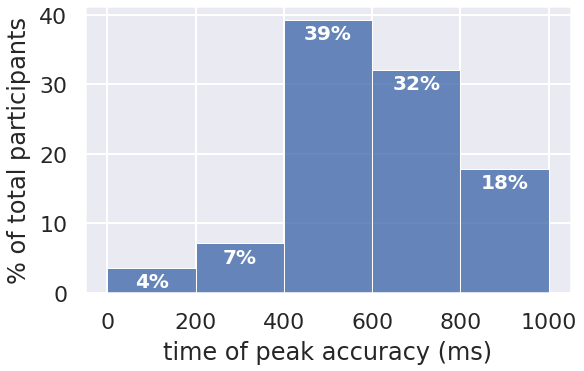

In [504]:
import matplotlib as mpl
with mpl.rc_context(params):
    plt.style.use('seaborn-darkgrid')
    sns.set_context("poster")
    fig, ax = plt.subplots(figsize=(8.7, 5.27))

    p = sns.histplot(data=diag_, 
                     x='best_train_test_time', 
                     stat='percent', 
                     binwidth=.2, 
                     binrange=(0,1), 
                     edgecolor="white",
                     linewidth=1,color='#4f74b1',
                     ax=ax, alpha=.855)
    for h in p.patches:
        height = h.get_height() 
        if height == 0: vert = + .35; color='gray'
        else: vert = -2.8; color='white'
        p.text(x = h.get_x() + (h.get_width()/2),
               y = height + vert, 
               s = '{:.0f}%'.format(height), 
               ha = 'center',
               fontsize=20,
               color=color,
               fontweight="bold")
    plt.xticks(np.arange(0,101,20)/100,np.arange(0,1001,200))
    ax.set(xlabel='time of peak accuracy (ms)',ylabel='% of total participants')
    
    figname = 'across_subject_distribution_of_peak_acc_across_time_w50s10_ridge_0.2bin-labeled-5.png'

    plt.savefig(result_path + '/clean/aim-2/'+ figname, dpi=450, bbox_inches = "tight", transparent=True)
    plt.show()

In [135]:
diag_.groupby(by='subject')['best_train_test_time'].mean()

subject
EP03    0.69
EP05    0.55
EP06    0.79
EP07    0.61
EP09    0.71
EP10    0.65
EP11    0.95
EP12    0.51
EP13    0.65
EP14    0.55
EP15    0.52
EP16    0.89
EP17    0.42
EP18    0.29
EP19    0.71
EP20    0.58
EP21    0.03
EP22    0.38
EP23    0.46
EP25    0.57
EP26    0.60
EP27    0.95
EP28    0.53
EP29    0.46
EP30    0.73
EP31    0.77
EP32    0.87
EP33    0.89
Name: best_train_test_time, dtype: float64

In [148]:
b = main_by_subj['w_best_diag_time'].values/1000
c = diag_.groupby(by='subject')['best_train_test_time'].mean().values
# np.array_equal(b,c)
[b==c]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False])]

In [212]:
main_by_subj

,index,Subject,Classifier,trial_window,trial_train_accuracy,trial_test_accuracy,window,step,Interference_effect,Duration,Duration_straight,Duration_reverse,w_best_diag_accuracy,w_best_diag_time
0,0,EP03,Ridge Classifier,1000,0.665000,0.666667,50,10,0.047638,0.383838,0.384892,0.382794,0.733333,690
1,146,EP05,Ridge Classifier,1000,0.578333,0.650000,50,10,0.104538,0.473641,0.478883,0.468364,0.733333,550
2,292,EP06,Ridge Classifier,1000,0.721667,0.716667,50,10,0.085249,0.425675,0.427492,0.423869,0.783333,790
3,438,EP07,Ridge Classifier,1000,0.933333,0.916667,50,10,0.220783,0.505401,0.502810,0.508045,0.933333,610
4,584,EP09,Ridge Classifier,1000,0.583333,0.616667,50,10,0.290090,0.519242,0.512091,0.526790,0.716667,710
5,730,EP10,Ridge Classifier,1000,0.860000,0.900000,50,10,0.250774,0.394975,0.393900,0.396060,0.900000,650
6,876,EP11,Ridge Classifier,1000,0.665000,0.600000,50,10,0.047529,0.416155,0.432434,0.399820,0.733333,950
7,1022,EP12,Ridge Classifier,1000,0.750000,0.750000,50,10,0.163884,0.527281,0.524431,0.530151,0.816667,510
8,1168,EP13,Ridge Classifier,1000,0.861667,0.900000,50,10,0.220331,0.402052,0.391449,0.412689,0.833333,650
9,1314,EP14,Ridge Classifier,1000,0.660000,0.650000,50,10,0.251179,0.484525,0.483815,0.485284,0.800000,550


In [183]:
diag_.groupby(by='subject',as_index=False)['best_train_test_time'].mean()

,subject,best_train_test_time
0,EP03,0.69
1,EP05,0.55
2,EP06,0.79
3,EP07,0.61
4,EP09,0.71
5,EP10,0.65
6,EP11,0.95
7,EP12,0.51
8,EP13,0.65
9,EP14,0.55


143.5 0.1
289.5 0.30000000000000004
1603.5 0.5
1311.5 0.7000000000000001
727.5 0.9


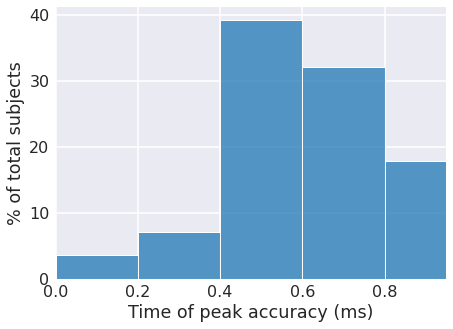

In [189]:
# diag_.groupby(by='subject')['best_train_test_time'].mean()
fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(data=diag_.groupby(by='subject',as_index=False)['best_train_test_time'].mean(), 
                 x='best_train_test_time', 
                 stat='percent', 
                 binwidth=.2, 
                 binrange=(0,1), 
                 edgecolor="white",
                 linewidth=1,
                 ax=ax)
plt.xlabel('Time of peak accuracy (ms)')
plt.ylabel('% of total subjects')
plt.xlim(0,.95)
plt.tick_params(axis='both',pad=6)

for h in p.patches:
    height = h.get_height() 
    if height == 0: vert = + .35; color='gray'
    else: vert = -2.5; color='white'
    p.text(x = (h.get_x() + (h.get_width()/2))*1000,
           y = height + vert, 
           s = '{:.0f}%'.format(height), 
           ha = 'center',
           fontsize=16,
           color=color,
          ) 
    print(height + vert,  h.get_x() + (h.get_width()/2),)
# plt.xticks(np.arange(0,101,20)/100,np.arange(0,1001,200))
figname = 'across_subject_distribution_of_peak_acc_across_time_w50s10_ridge_0.2bin-labeled.png'
# plt.savefig(result_path + '/clean/aim-2/' figname, dpi=450, bbox_inches = "tight", transparent=True)
plt.show()

In [151]:
b

array([0.69, 0.55, 0.79, 0.61, 0.71, 0.65, 0.95, 0.51, 0.65, 0.55, 0.52,
       0.89, 0.42, 0.29, 0.71, 0.58, 0.03, 0.38, 0.46, 0.57, 0.6 , 0.95,
       0.53, 0.46, 0.73, 0.77, 0.87, 0.89])

In [156]:
list([b[i]-c[i]] for i in np.arange(28))

[[1.3322676295501878e-15],
 [1.5543122344752192e-15],
 [-2.3314683517128287e-15],
 [4.440892098500626e-16],
 [1.887379141862766e-15],
 [-1.2212453270876722e-15],
 [-8.881784197001252e-16],
 [-1.1102230246251565e-16],
 [-1.2212453270876722e-15],
 [1.5543122344752192e-15],
 [-5.551115123125783e-16],
 [-1.1102230246251565e-16],
 [-1.2212453270876722e-15],
 [6.106226635438361e-16],
 [1.887379141862766e-15],
 [1.2212453270876722e-15],
 [5.551115123125783e-17],
 [-8.881784197001252e-16],
 [-4.440892098500626e-16],
 [1.3322676295501878e-15],
 [7.771561172376096e-16],
 [-8.881784197001252e-16],
 [-7.771561172376096e-16],
 [-4.440892098500626e-16],
 [-7.771561172376096e-16],
 [8.881784197001252e-16],
 [-1.7763568394002505e-15],
 [-1.1102230246251565e-16]]

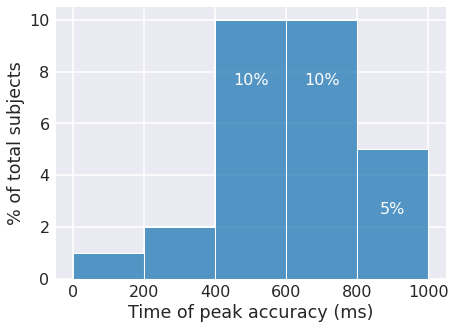

In [157]:
fig, ax = plt.subplots(figsize=(7, 5))
p = sns.histplot(data=main_by_subj, 
                 x='w_best_diag_time', 
                 stat='count', 
                 binwidth=200, 
                 binrange=(0,1000), 
                 edgecolor="white",
                 linewidth=1,
                 ax=ax)

for h in p.patches:
    height = h.get_height() 
    if height == 0: vert = + .35; color='gray'
    else: vert = -2.5; color='white'
    p.text(x = h.get_x() + (h.get_width()/2),
           y = height + vert, 
           s = '{:.0f}%'.format(height), 
           ha = 'center',
           fontsize=16,
           color=color,
          ) 
plt.xlabel('Time of peak accuracy (ms)')
plt.ylabel('% of total subjects')
# plt.xlim(0,.95)
plt.tick_params(axis='both',pad=6)
figname = 'across_subject_distribution_of_peak_acc_across_time_w50s10_ridge_0.2bin-labeled.png'
# plt.savefig(result_path + '/clean/aim-2/' figname, dpi=450, bbox_inches = "tight", transparent=True)
plt.show()

In [124]:
main_by_subj['w_best_diag_time']

0     690
1     550
2     790
3     610
4     710
5     650
6     950
7     510
8     650
9     550
10    520
11    890
12    420
13    290
14    710
15    580
16     30
17    380
18    460
19    570
20    600
21    950
22    530
23    460
24    730
25    770
26    870
27    890
Name: w_best_diag_time, dtype: int64

In [ ]:
who